In [1]:
from anemone.inversion import *
from anemone.forwards import Forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
import matplotlib.pyplot as plt

In [2]:
def compute_relstd(t_gates, data_val, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1, relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = data_val*current
    std_rel = abs_noise/y.T
    relstd_tot = torch.sqrt(std_rel**2 + relative_noise**2)
    return relstd_tot.to(data_val.device).T

In [8]:
from anemone.forwards import drte_dsigma

class Forward2(Forward):
    def jacobian(self):
    # dRTE = drte_dsigma(self.sigma.to(torch.complex64), self.thick.to(torch.complex64), self.omegajac, self.lamdajac).squeeze()
        with torch.no_grad():
            dRTE = drte_dsigma(self.sigma, self.thick, self.omega, self.lamda).squeeze().real.to(rdtype).T
            
            if len(dRTE.shape)>2:
                Gr = torch.einsum('ijk,lk->jil', dRTE, self.H2t)
                # Gr /= (self.rho.real.squeeze().T**2)[:,:,None]
            else:
                Gr = torch.einsum('ik,...k->i...', self.H2t, dRTE).T
                Gr /= (self.rho.real.squeeze()**2)[:,None]
            return Gr

In [9]:
gpu = torch.device('cpu')
print('number of threads: ', torch.get_num_threads())


t1 = torch.logspace(-6, -4, 15)
t2 = torch.logspace(-5, -3, 31)
tx = Loop.square(3)
rx = Receiver(x=10.)

wv1 = Waveform(torch.tensor([-0.5e-3, -0.9e-3, 0., 0.5e-6]), torch.tensor([0, 1, 1, 0]))
wv2 = Waveform(torch.tensor([-1e-3, -1.5e-3, 0., 0.5e-5]), torch.tensor([0, 1, 1, 0]))

fwr1 = Forward2(tx, rx, t1, waveform=wv1, tolerance=1e-6, do_setup=False, log_scale=True)
fwr2 = Forward2(tx, rx, t2, waveform=wv2, tolerance=1e-6, do_setup=False, log_scale=True)
# fwr2.set_device(gpu)

fwr = fwr1 + fwr2
fwr.set_device(gpu)

number of threads:  28


In [10]:
n_mods = 100

z = torch.cumsum(torch.logspace(0, 1, 30), 0)
z /= z.max()

z *= 120.
print(z)

rho_true = torch.tensor([175., 5., 200.], device=gpu, dtype=rdtype)
thk_true = torch.tensor([5, 1], device=gpu, dtype=rdtype)

n_mod_ones = torch.ones(n_mods, device=gpu, dtype=rdtype)
rho2d = rho_true[:, None]*n_mod_ones[None,:]
thk2d = thk_true[:, None]*n_mod_ones[None,:]



res_start = LogResistivity.smooth(torch.ones(len(z)+1)*50., z)
thick1 = torch.linspace(0, 30, n_mods).to(rdtype).to(gpu)

thk2d[1] += thick1

dbdts = fwr(rho2d, thk2d)
d_errs = compute_relstd(fwr.times, dbdts.exp().T, current=10.).T
dbdt_obs = dbdts.exp()# * (1+d_errs*torch.randn_like(dbdts))
d_errs[dbdt_obs<0.] = torch.inf

d_obss = torch.abs(dbdt_obs).log()

tensor([  1.0092,   2.1017,   3.2846,   4.5652,   5.9516,   7.4525,   9.0776,
         10.8369,  12.7416,  14.8036,  17.0361,  19.4531,  22.0698,  24.9027,
         27.9698,  31.2903,  34.8852,  38.7771,  42.9907,  47.5525,  52.4912,
         57.8381,  63.6268,  69.8939,  76.6788,  84.0245,  91.9772, 100.5870,
        109.9084, 120.0000])


In [11]:
class LCI2(LCI):
    def jacobian(self, mvec):
        if self.one_over_error is None:
            self.n_sites = len(self.inv_list)
            self.one_over_error = torch.sqrt(self.recip_error_squared).reshape(self.n_sites, -1)[:, None, :]
            self._dobsgrid = self.data_observed.reshape(self.n_sites, -1)
            self._derrgrid = self.data_error.reshape(self.n_sites, -1)**2
            _,thick = self.inv_list[0].model.mod
            self.Ggrid = torch.empty((self.n_sites, len(thick)+1, self._dobsgrid.shape[-1]), dtype=rdtype, device=self.device)
        mvecs = mvec.reshape(self.n_sites, -1).T
        _,thick = self.inv_list[0].model.mod
        rhos = mvecs.exp()
        
        if hasattr(self.inv_list[0].forward, 'device'):
            rhos = rhos.to(self.inv_list[0].forward.device)
            thick = thick.to(self.inv_list[0].forward.device)

        if self.reuse_jac:
            mvec0 = mvecs[:, 0]
            Gsingle = self.inv_list[0].forward(rhos[:, 0], thick, jac=True)
            self.Ggrid[0] = Gsingle
            for i_site in range(1, self.n_sites):
                cvec = mvecs[:, i_site]
                rel_diff = torch.abs(cvec - mvec0) / torch.abs(mvec0)
                if torch.all(rel_diff > 1e-1):
                    mvec0 = cvec
                    Gsingle = self.inv_list[i_site].forward(rhos[:, i_site], thick, jac=True)
                self.Ggrid[i_site] = Gsingle

                    
        # else:
        #     batch=250
        #     if self.n_sites<batch:
        #         self.Ggrid = self.inv_list[0].forward(rhos, thick, jac=True)
        #     else:
        #         i=0
        #         while (i+2)*batch<self.n_sites:
        #             self.Ggrid[i*batch:(i+1)*batch] = self.inv_list[0].forward(rhos[:, i*batch:(i+1)*batch], thick, jac=True)
        #             i += 1
        #         self.Ggrid[i*batch:] = self.inv_list[0].forward(rhos[:, i*batch:], thick, jac=True)
        else:
            for i_site in range(self.n_sites):
                self.Ggrid[i_site] = self.inv_list[0].forward(rhos[:,i_site], thick, jac=True)

        self.Ggrid /= self._dpredgrid.exp()[:, None, :]
        self.Ggrid *= rhos.cpu().T[:,:,None]
        r_data = torch.einsum('ijk,ijk->ij', self.Ggrid, ((self._dobsgrid-self._dpredgrid)/self._derrgrid)[:, None, :])
        self.Ggrid *= self.one_over_error

        GtG = self.Ggrid @ self.Ggrid.swapaxes(-1,-2)
        GtG_np = GtG.cpu().numpy()  # shape: (n_sites, br, bc)
        n_blocks, br, bc = GtG_np.shape
        

        if self._GtG is None:
            indices = np.arange(n_blocks, dtype=np.int32)      # one diag block per row-block
            indptr  = np.arange(n_blocks + 1, dtype=np.int32)  # cumulative count

            self._GtG = sp.sparse.bsr_matrix(
                (GtG_np.copy(), indices, indptr),
                shape=(n_blocks * br, n_blocks * bc),
            )
            self.blocksize = (br, bc)
            eye_block = np.eye(br, bc, dtype=GtG_np.dtype)
            eye_blocks = np.repeat(eye_block[None, :, :], n_blocks, axis=0)
            self.Imod = sp.sparse.bsr_matrix(
                (eye_blocks, indices, indptr),
                shape=self._GtG.shape,
            )
        else:
            self._GtG.data[...] = GtG_np*1.  # no flattening
        
        self._r_data = r_data.cpu().numpy().flatten()
        self.cmvec = self.mvec.cpu().numpy()*1.
    
    def misfit(self):
        return (self.r_data @ self.r_data) / (len(self.data_observed)+self.Rp.shape[0]+self.RL.shape[0])

    @property
    def stop_inversion(self):
        self.iteration += 1
        return self.iteration>=self.iter_cap

In [13]:
inv_list = []
m_trues=[]
from time import time as timer
bt = timer()

this_fwr = fwr.copy()
this_fwr.set_device(gpu)

for i,dthick in enumerate(thick1):
    tmp_inv = Tikhonov(d_obss[i], torch.log1p(d_errs[i]), res_start.copy(), this_fwr)
    inv_list.append(tmp_inv)    

print(f"Created {len(inv_list)} inversions in {timer()-bt:.2f} seconds")

# import cProfile
# import pstats
# profiler = cProfile.Profile()
# profiler.enable()

lci = LCI(inv_list)
lci.iteration=0
print(lci.iteration)

lci.horizontal_smoothness=0.002
lci.vertical_smoothness=0.002
lci.reuse_jac = True


res_mods= lci.invert(iter_cap=25)
# dois = lci.doi
# profiler.disable()
# stats = pstats.Stats(profiler)
# stats.sort_stats('cumtime').print_stats(20)  # Print top 20 by cumulative time

Created 100 inversions in 0.21 seconds
0
000	Total misfit increased, smaller step	


\\uni.au.dk\dfs\Nat-Tech_HGG-People\matt.griffiths\_GIT\anemone\src\anemone\inversion\inversion.py:592: MatrixRankWarning: Matrix is exactly singular
  dm = sp.sparse.linalg.spsolve(Aown, self._r_data)


000	Total misfit increased, smaller step	
000	Total misfit increased, smaller step	
000	Total misfit increased, smaller step	
000	Total misfit increased, smaller step	


KeyboardInterrupt: 

In [ ]:
# tmp_inv.set_device(gpu)
# r1 = tmp_inv.invert()

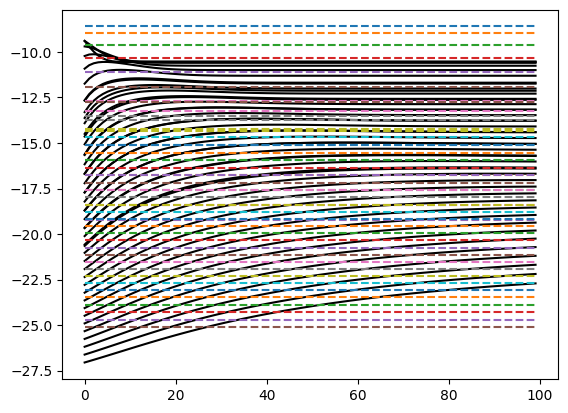

In [ ]:
plt.figure()
plt.plot(d_obss, 'k-')
plt.plot(lci._dpred.reshape(lci.n_sites, -1), '--')

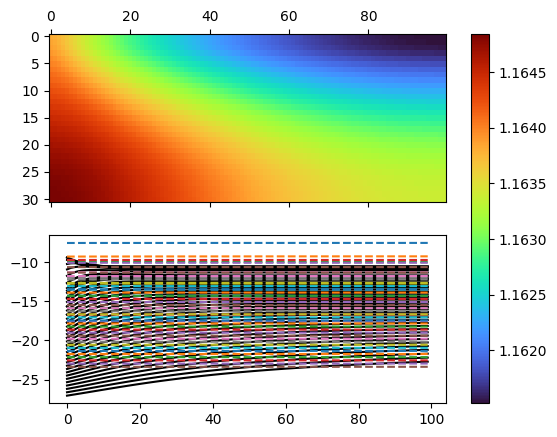

In [9]:
import matplotlib.pyplot as plt

fig,ax = plt.subplots(2,1)
pcm=ax[0].matshow(lci.mvec.reshape(n_mods, -1).exp().log10().T, aspect='auto', cmap='turbo')
ax[1].plot(d_obss, 'k-')
ax[1].plot(lci._dpred.reshape(lci.n_sites, -1), '--')
plt.colorbar(pcm, ax=ax)
plt.show()

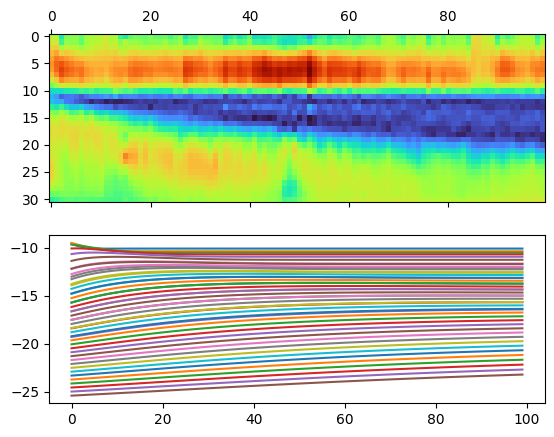